## Objective

The objective of this project is to develop a Machine Learning classification model using the Random Forest algorithm to predict customer churn. The notebook performs data cleaning, exploratory data analysis (EDA), feature preprocessing, and class imbalance handling using SMOTE. It evaluates model performance using a confusion matrix and classification report, identifies important features influencing churn, and predicts potential churners among newly joined customers to support proactive customer retention strategies.

## Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
import joblib



In [2]:
from IPython.display import display
pd.set_option("display.max_columns", None)

## Load Dataset

In [3]:
data = pd.read_csv(r"prod_Churn.csv")

display(data.head())

,customer_id,gender,age,married,state,number_of_referrals,tenure_in_months,value_deal,phone_service,multiple_lines,internet_service,internet_type,online_security,online_backup,device_protection_plan,premium_support,streaming_tv,streaming_movies,streaming_music,unlimited_data,contract,paperless_billing,payment_method,monthly_charge,total_charges,total_refunds,total_extra_data_charges,total_long_distance_charges,total_revenue,customer_status,churn_category,churn_reason
0,19877-DEL,Male,35,No,Delhi,7,27,NaN,Yes,No,Yes,Cable,No,Yes,No,Yes,Yes,No,No,Yes,One Year,Yes,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,Others,Others
1,58353-MAH,Female,45,Yes,Maharashtra,14,13,NaN,Yes,Yes,Yes,Cable,No,No,No,No,No,Yes,Yes,No,Month-to-Month,No,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,Others,Others
2,25063-WES,Male,51,No,West Bengal,4,35,Deal 5,Yes,No,Yes,Fiber Optic,No,No,Yes,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,59787-KAR,Male,79,No,Karnataka,3,21,Deal 4,Yes,No,Yes,Fiber Optic,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,28544-TAM,Female,80,No,Tamil Nadu,3,8,NaN,Yes,No,Yes,Fiber Optic,No,No,No,Yes,Yes,No,No,Yes,Month-to-Month,Yes,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [4]:
print(f"Shape of the data: {data.shape}")

Shape of the data: (6418, 32)


In [5]:
pred_data = data[data["customer_status"].isin(["Stayed", "Churned"])].copy()

pred_data.shape

(6007, 32)

In [6]:
display(pred_data.head())

,customer_id,gender,age,married,state,number_of_referrals,tenure_in_months,value_deal,phone_service,multiple_lines,internet_service,internet_type,online_security,online_backup,device_protection_plan,premium_support,streaming_tv,streaming_movies,streaming_music,unlimited_data,contract,paperless_billing,payment_method,monthly_charge,total_charges,total_refunds,total_extra_data_charges,total_long_distance_charges,total_revenue,customer_status,churn_category,churn_reason
0,19877-DEL,Male,35,No,Delhi,7,27,NaN,Yes,No,Yes,Cable,No,Yes,No,Yes,Yes,No,No,Yes,One Year,Yes,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,Others,Others
1,58353-MAH,Female,45,Yes,Maharashtra,14,13,NaN,Yes,Yes,Yes,Cable,No,No,No,No,No,Yes,Yes,No,Month-to-Month,No,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,Others,Others
2,25063-WES,Male,51,No,West Bengal,4,35,Deal 5,Yes,No,Yes,Fiber Optic,No,No,Yes,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,59787-KAR,Male,79,No,Karnataka,3,21,Deal 4,Yes,No,Yes,Fiber Optic,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,28544-TAM,Female,80,No,Tamil Nadu,3,8,NaN,Yes,No,Yes,Fiber Optic,No,No,No,Yes,Yes,No,No,Yes,Month-to-Month,Yes,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [7]:
pred_data.select_dtypes(include=["float", "int"]).columns

Index(['age', 'number_of_referrals', 'tenure_in_months', 'monthly_charge',
       'total_charges', 'total_refunds', 'total_extra_data_charges',
       'total_long_distance_charges', 'total_revenue'],
      dtype='object')

In [8]:
categorical_feature = pred_data.select_dtypes(include=['object', 'category'])

cat_unique_df = pd.DataFrame([
    {
        "Columns": col,
        "Unique Count": pred_data[col].nunique(),
        "Unique Values": pred_data[col].unique().tolist(),
        "Missing Value": pred_data[col].isna().sum(),
        "Missing Pct%": pred_data[col].isna().sum() * 100.0 / len(pred_data)
        
    }
    for col in categorical_feature.columns
])

display(cat_unique_df)

,Columns,Unique Count,Unique Values,Missing Value,Missing Pct%
0,customer_id,6007,"[19877-DEL, 58353-MAH, 25063-WES, 59787-KAR, 2...",0,0.000000
1,gender,2,"[Male, Female]",0,0.000000
2,married,2,"[No, Yes]",0,0.000000
3,state,22,"[Delhi, Maharashtra, West Bengal, Karnataka, T...",0,0.000000
4,value_deal,5,"[nan, Deal 5, Deal 4, Deal 1, Deal 2, Deal 3]",3297,54.885966
5,phone_service,2,"[Yes, No]",0,0.000000
6,multiple_lines,2,"[No, Yes]",0,0.000000
7,internet_service,2,"[Yes, No]",0,0.000000
8,internet_type,3,"[Cable, Fiber Optic, DSL, nan]",1223,20.359580
9,online_security,2,"[No, Yes]",0,0.000000


In [9]:
numeric_feature = pred_data.select_dtypes(include=['int64', 'float64']).columns

num_unique_df = pd.DataFrame([
    {
        "Columns": col,
        "Dtypes": pred_data[col].dtypes,
        "Missing Value": pred_data[col].isna().sum(),
        "Missing Pct%": pred_data[col].isna().sum() * 100.0 / len(pred_data)
        
    }
    for col in numeric_feature
])

display(num_unique_df)

,Columns,Dtypes,Missing Value,Missing Pct%
0,age,int64,0,0.0
1,number_of_referrals,int64,0,0.0
2,tenure_in_months,int64,0,0.0
3,monthly_charge,float64,0,0.0
4,total_charges,float64,0,0.0
5,total_refunds,float64,0,0.0
6,total_extra_data_charges,int64,0,0.0
7,total_long_distance_charges,float64,0,0.0
8,total_revenue,float64,0,0.0


In [10]:
pred_data["internet_type"] = pred_data["internet_type"].fillna(
    pred_data["internet_type"].mode()[0]
)

In [11]:
target_df = pd.DataFrame({
    "Value_Counts": pred_data["customer_status"].value_counts(),
    "Value_pct": pred_data["customer_status"].value_counts(normalize=True).mul(100).round(2)
})

display(target_df)

,Value_Counts,Value_pct
customer_status,,
Stayed,4275,71.17
Churned,1732,28.83


### Insights:
* customer_id, churn_category, churn_reason, value_deal, state are dropped, not required for modelling.
* Missing value in internet_type is imputed by median value.
* The Data set in not much imbalanced.

### Numerical Feature Analysis

In [12]:
import os
os.makedirs("eda", exist_ok=True)

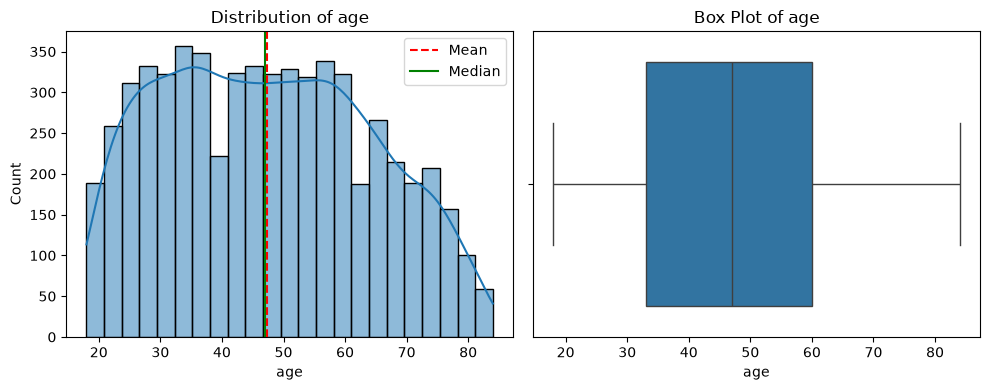

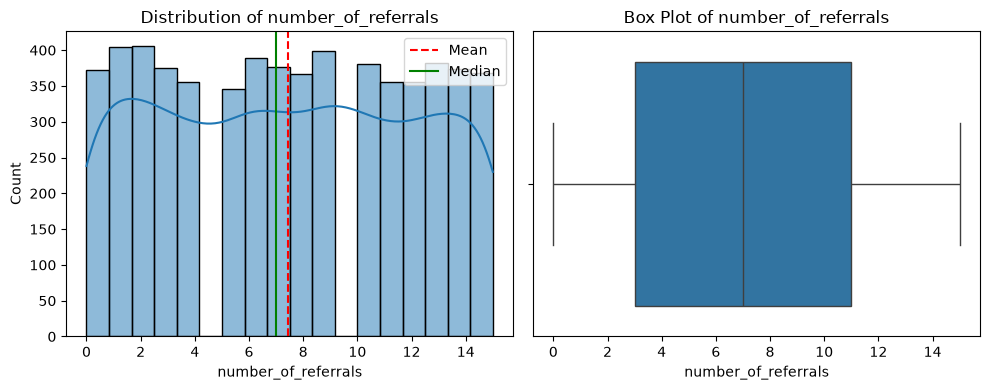

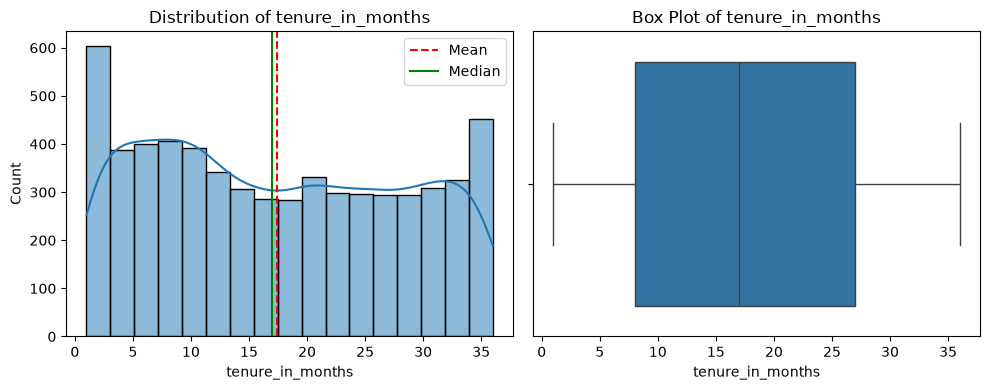

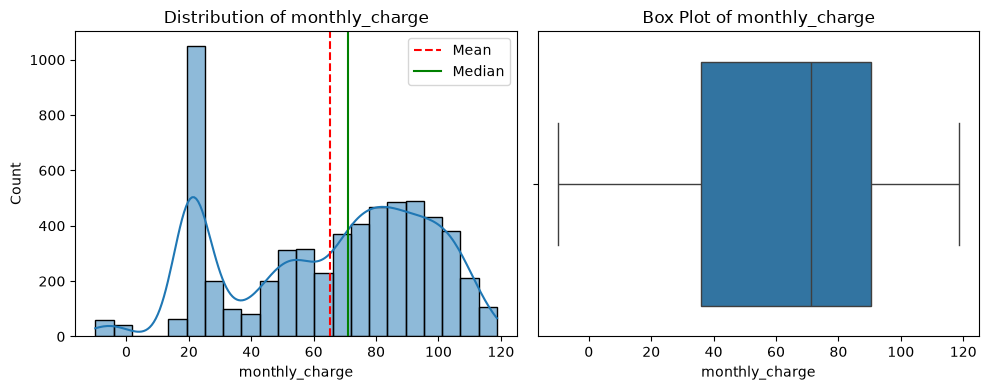

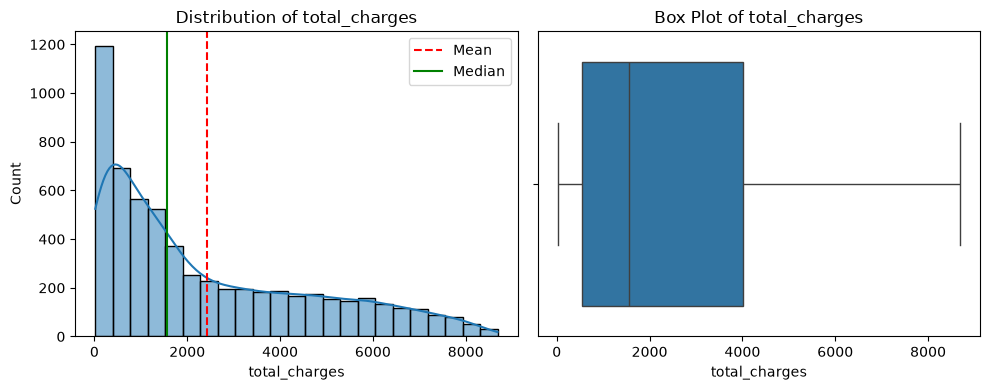

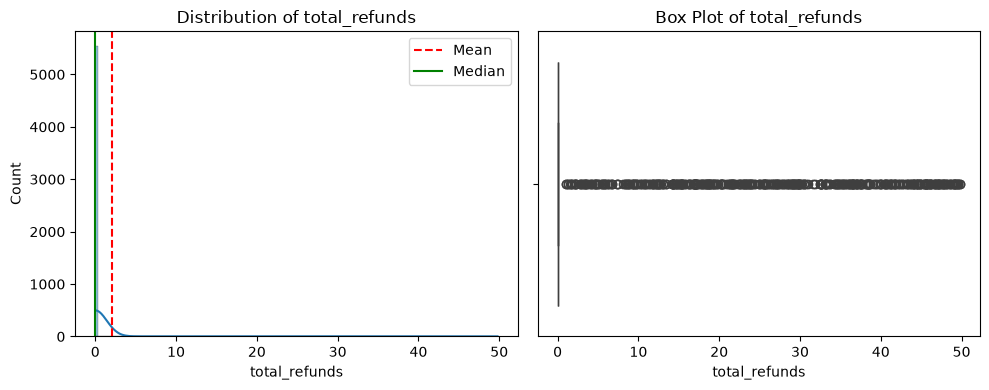

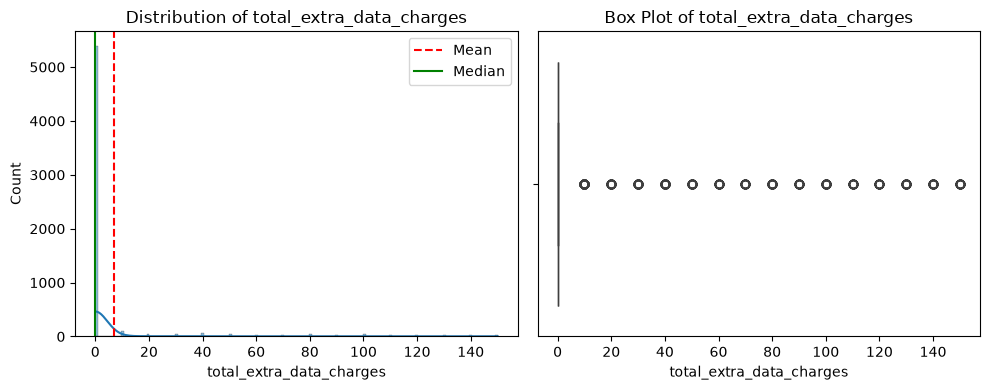

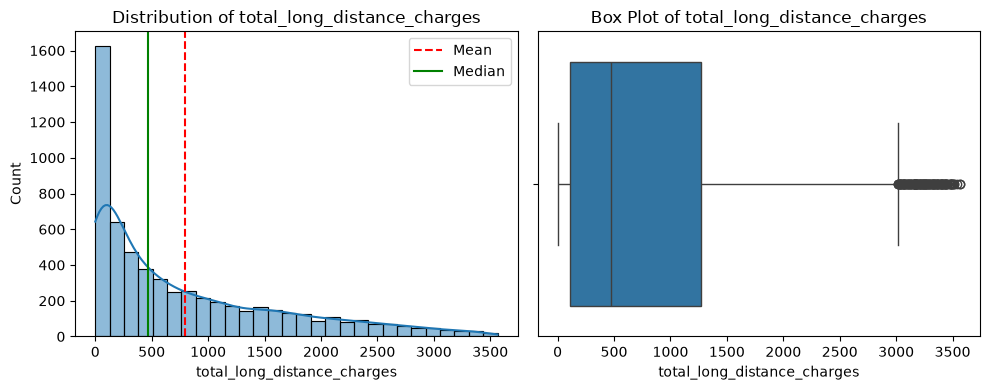

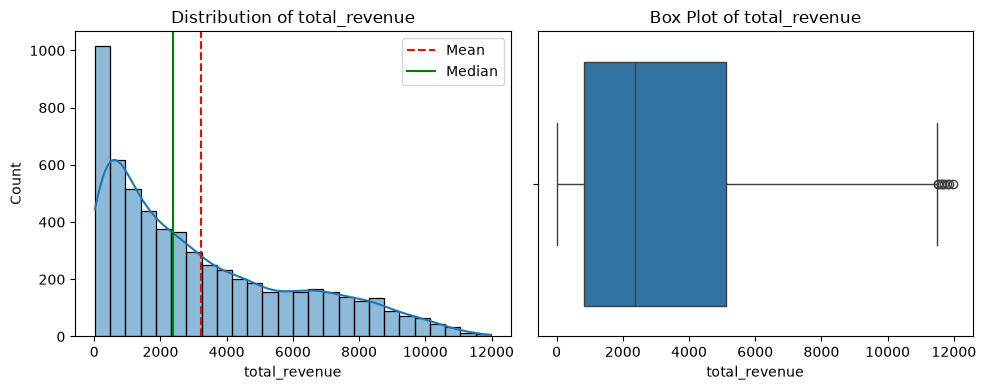

In [14]:
def plot(pred_data, column_name):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    # Histogram
    sns.histplot(pred_data[column_name].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {column_name}")

    col_mean = pred_data[column_name].mean()
    col_median = pred_data[column_name].median()

    axes[0].axvline(col_mean, color="red", linestyle="--", label="Mean")
    axes[0].axvline(col_median, color="green", linestyle="-", label="Median")
    axes[0].legend()

    # Box plot
    sns.boxplot(x=pred_data[column_name], ax=axes[1])
    axes[1].set_title(f"Box Plot of {column_name}")

    plt.tight_layout()

    # Save both plots in one image
    file_path = os.path.join("eda", f"{column_name}_hist_boxplot.png")
    plt.savefig(file_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close()


for col in numeric_feature:
    plot(pred_data, col)

### Correlation Heatmap for numerical columns

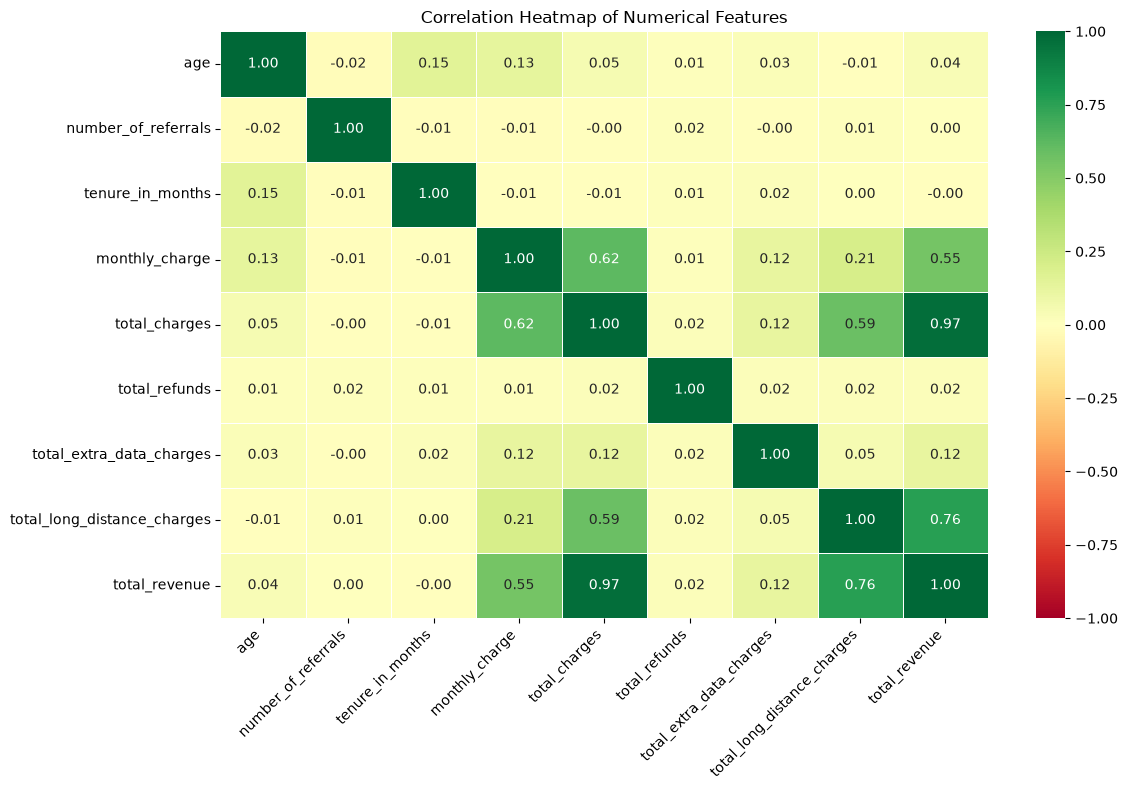

In [15]:
def plot_correlation_heatmap(pred_data):

    numerical_data = pred_data[numeric_feature]

    corr_matrix = numerical_data.corr()

    # Plot heatmap
    plt.figure(figsize=(12, 8))

    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap="RdYlGn",
        fmt=".2f",
        linewidths=0.5,
        vmin=-1,
        vmax=1,
        center=0
    )

    plt.title("Correlation Heatmap of Numerical Features")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    # Save figure
    plt.savefig(
        os.path.join("eda", "correlation_heatmap.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

plot_correlation_heatmap(pred_data)

### Categorical Feature Analysis

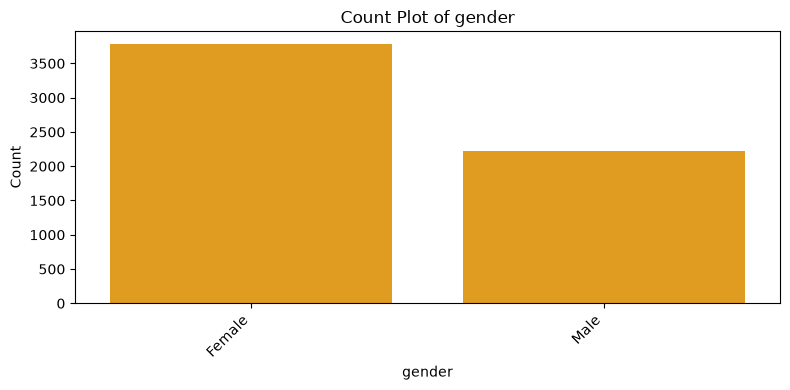

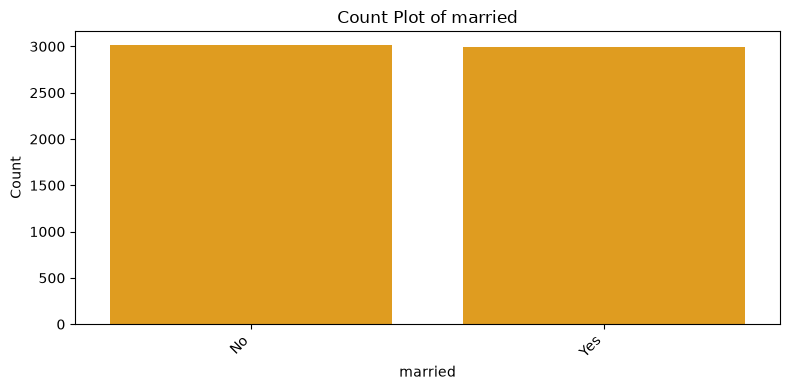

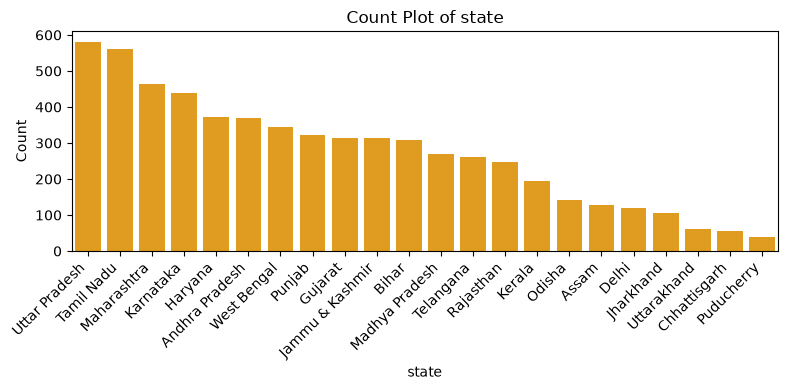

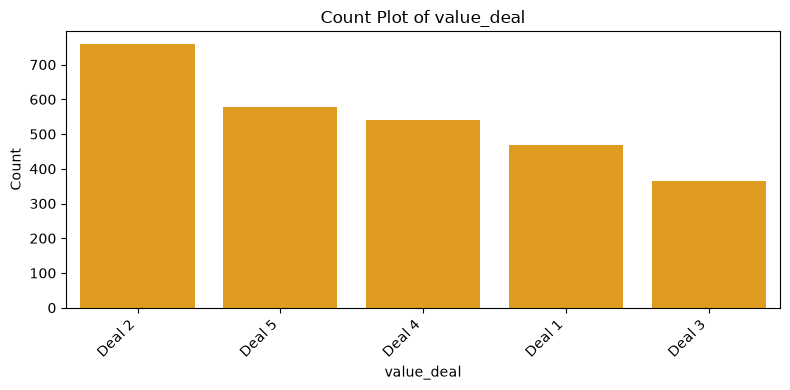

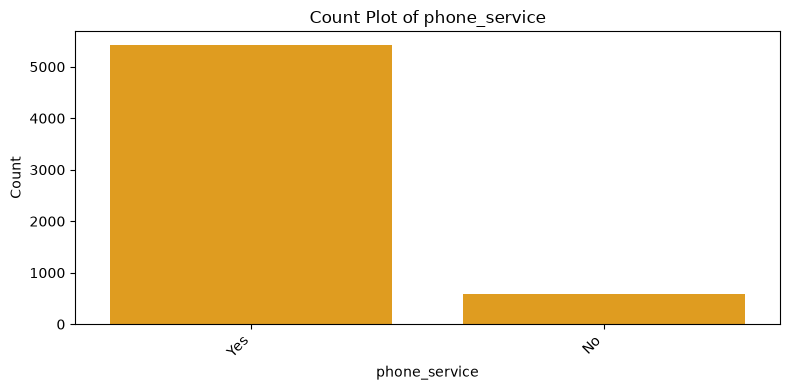

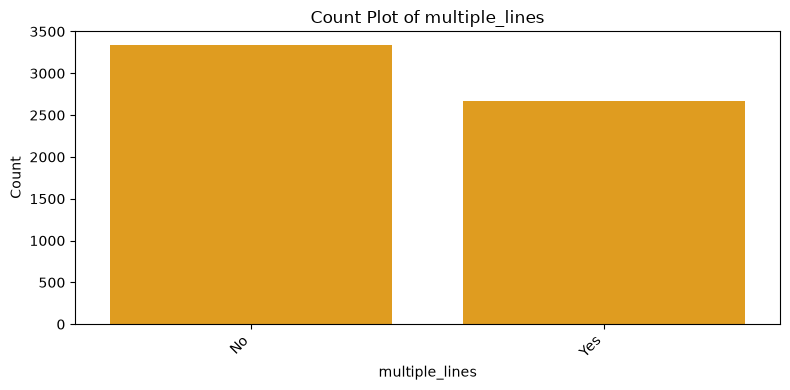

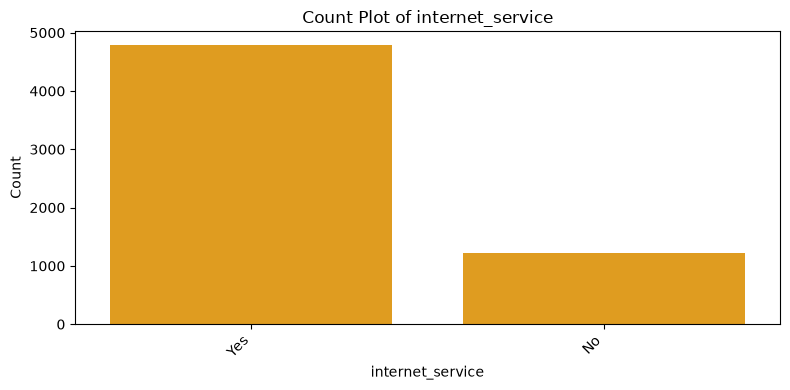

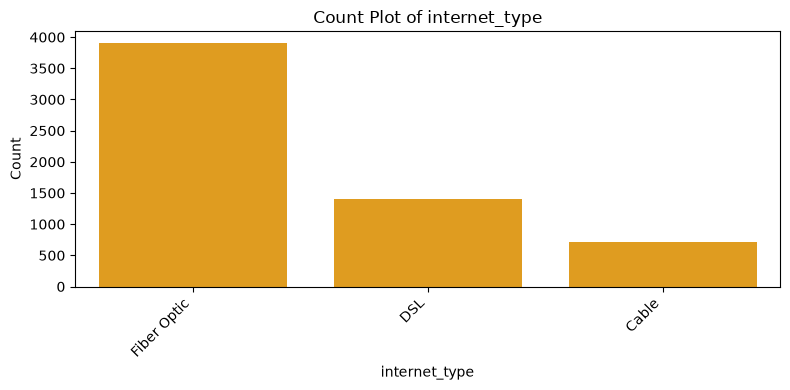

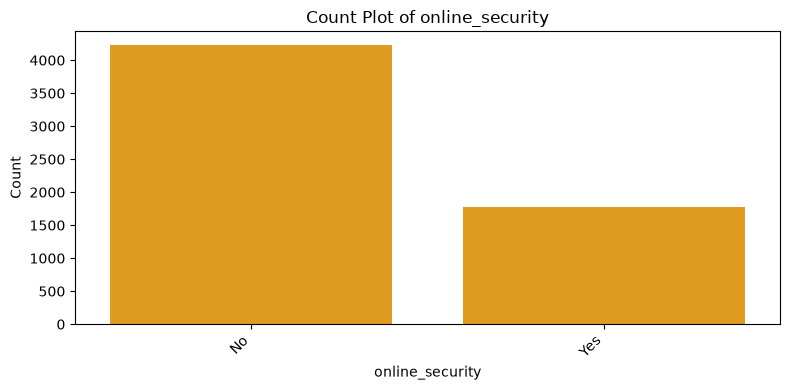

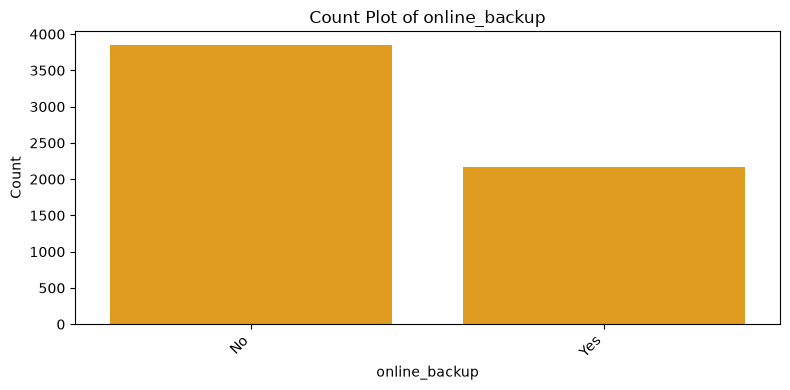

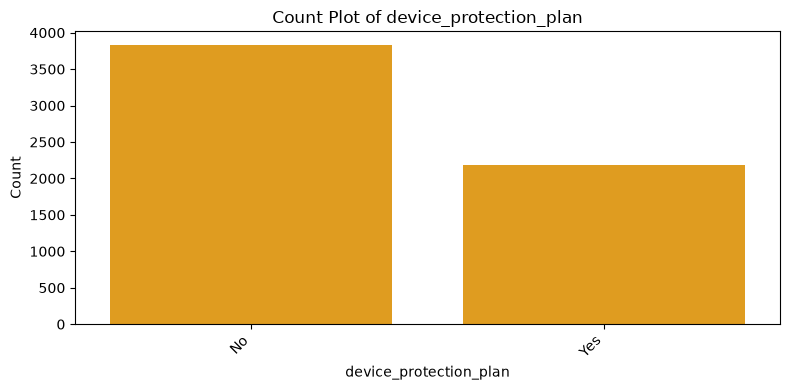

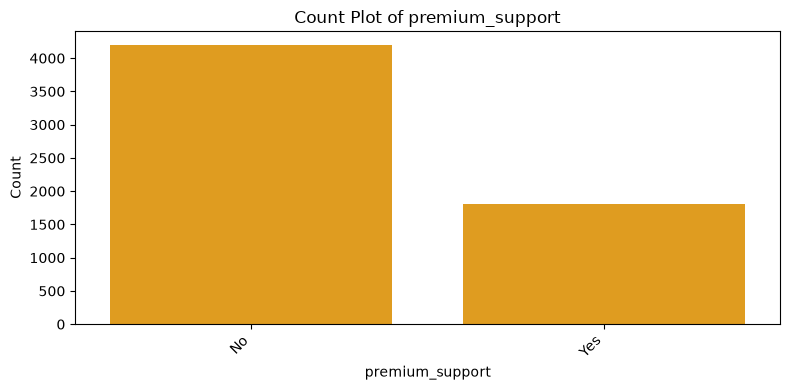

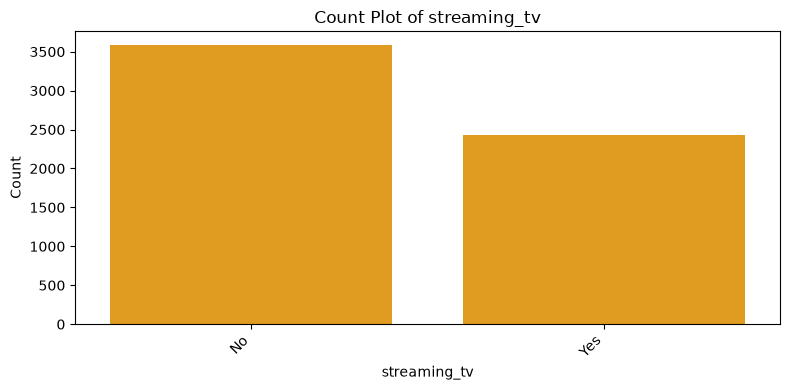

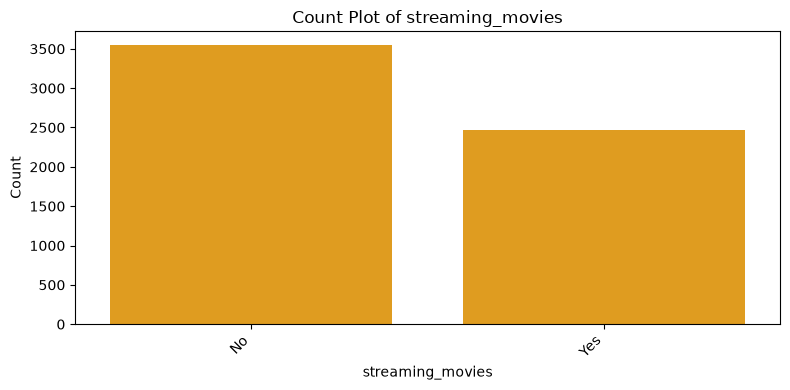

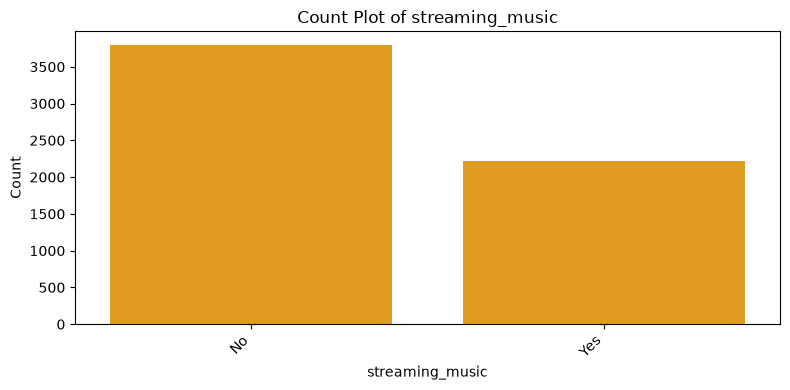

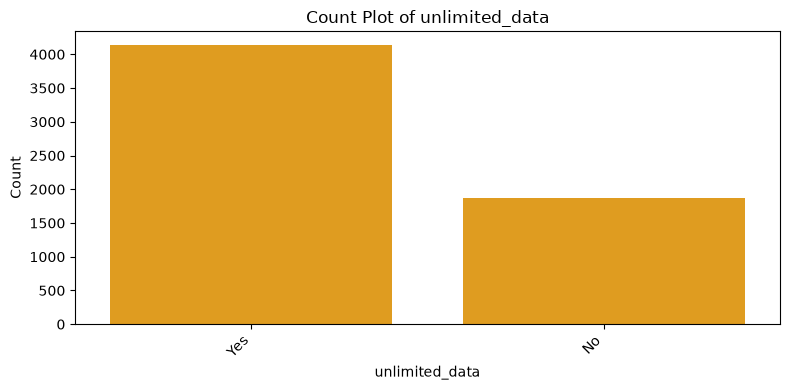

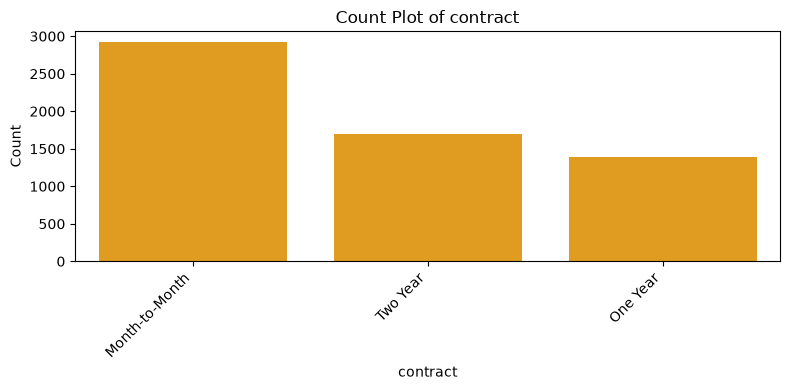

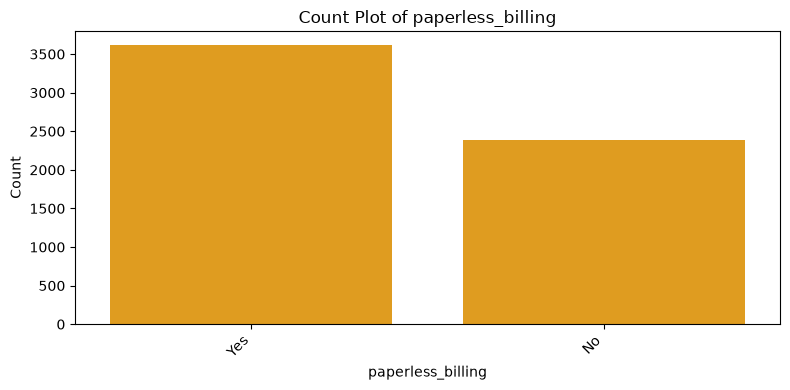

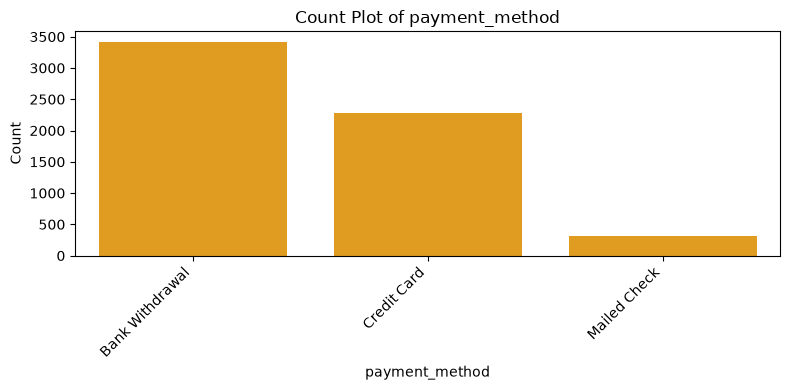

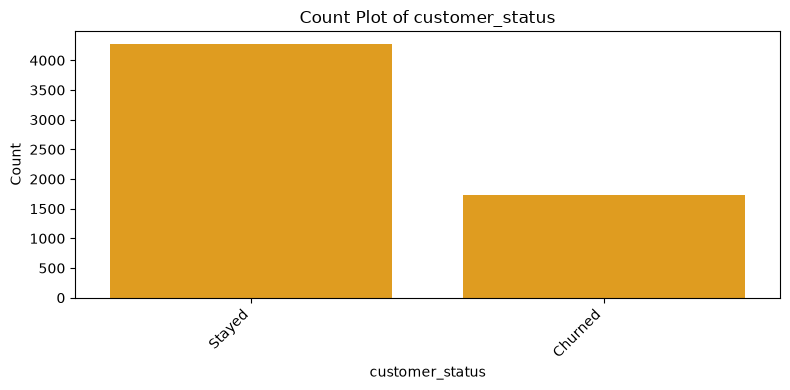

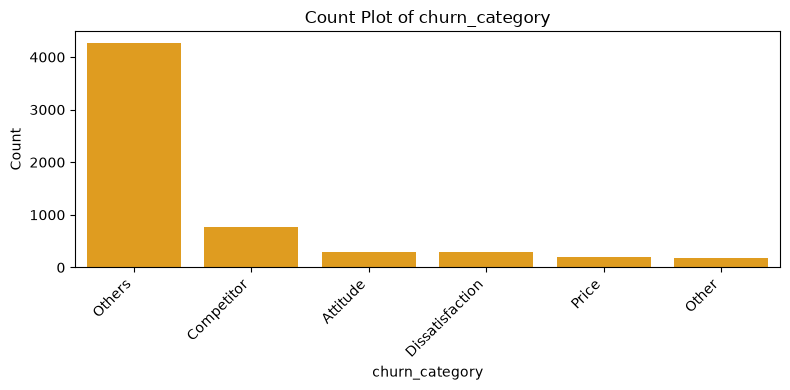

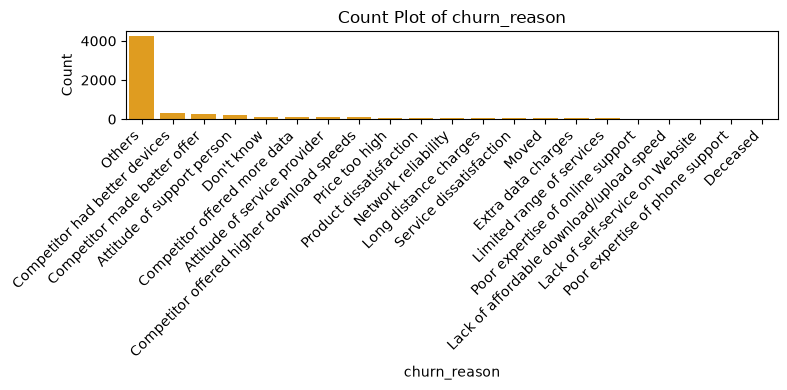

In [16]:
categorical_columns = categorical_feature.drop(['customer_id'], axis=1).columns

def plot_countplots(pred_data, categorical_columns):

    for col in categorical_columns:
        plt.figure(figsize=(8, 4))

        sns.countplot(
            data=pred_data,
            x=col,
            order=pred_data[col].value_counts().index,
            color="orange"
        )

        plt.title(f"Count Plot of {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()

        file_path = os.path.join("eda", f"{col}_countplot.png")
        plt.savefig(file_path, dpi=300, bbox_inches="tight")

        plt.show()
        plt.close()

plot_countplots(pred_data, categorical_columns)

## Train-Test Split

In [17]:
# Split data into features and target
pred_data = pred_data.drop(['customer_id', 'churn_category', 'churn_reason', 'value_deal', 'state'], axis=1)

target = 'customer_status'

X = pred_data.drop(target, axis=1)

y = pred_data[target]

y = pred_data[target].map({
    'Churned': 1,
    'Stayed': 0
})

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [18]:
# Categorical columns
columns_to_encode = [
    'gender', 'married', 'phone_service', 'multiple_lines',
    'internet_service', 'internet_type', 'online_security', 'online_backup',
    'device_protection_plan', 'premium_support', 'streaming_tv', 'streaming_movies',
    'streaming_music', 'unlimited_data', 'contract', 'paperless_billing',
    'payment_method'
]

# Numerical columns
columns_to_scale = [
    'age', 'number_of_referrals', 'tenure_in_months', 'monthly_charge',
    'total_charges', 'total_refunds', 'total_extra_data_charges',
    'total_long_distance_charges', 'total_revenue'
]

# Column Transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical_onehot',
            OneHotEncoder(handle_unknown='ignore', drop='first'),
            columns_to_encode
        ),
        (
            'numerical_scaler',
            StandardScaler(),
            columns_to_scale
        ),
    ],
    remainder='passthrough'
)



X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

#### Apply Smote to handle class imbalance.

In [19]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Check class distribution before SMOTE
print("Before SMOTE:", Counter(y_train))

# Apply SMOTE only to training data
smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_processed, y_train
)

# Check class distribution after SMOTE
print("After SMOTE:", Counter(y_train_resampled))

Before SMOTE: Counter({0: 3420, 1: 1385})
After SMOTE: Counter({0: 3420, 1: 3420})


### Training Model

#### Training Random Forest Model

Confusion Matrix:


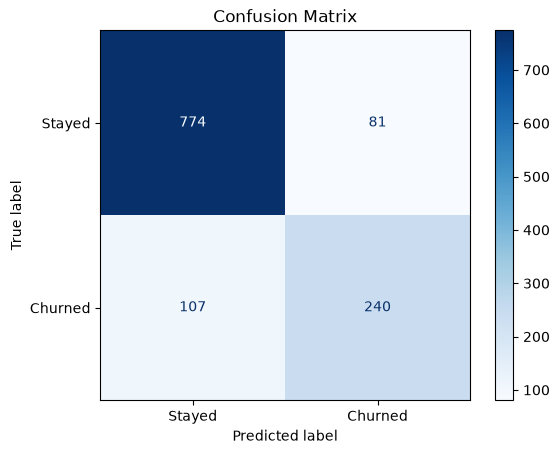

              precision    recall  f1-score   support

           0       0.88      0.91      0.89       855
           1       0.75      0.69      0.72       347

    accuracy                           0.84      1202
   macro avg       0.81      0.80      0.81      1202
weighted avg       0.84      0.84      0.84      1202



In [20]:
rf_model = RandomForestClassifier(
            n_estimators=300,      
            criterion="gini",        
            max_depth=20,            
            min_samples_split=5,     
            min_samples_leaf=2,      
            max_features="sqrt",     
            bootstrap=True,              
            class_weight=None,       
            random_state=42,
            n_jobs=-1           
)
# Train the model
rf_model.fit(X_train_resampled, y_train_resampled)

# Make predictions
y_pred = rf_model.predict(X_test_processed)

# Evaluate the model
print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)

# Plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Stayed', 'Churned']
)

disp.plot(cmap='Blues')

plt.title('Confusion Matrix')
plt.show()

print(classification_report(y_test, y_pred))


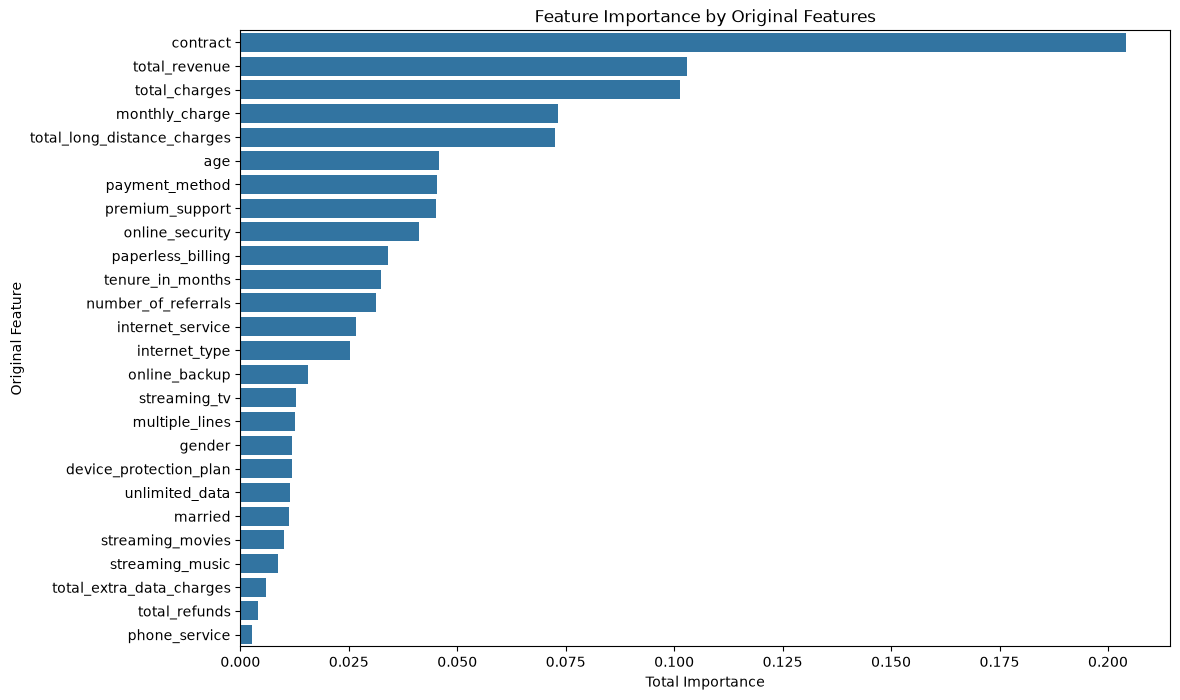

In [21]:
feature_names = preprocessor.get_feature_names_out()

# feature importances from Random Forest
importances = rf_model.feature_importances_

# Create dataframe
feature_importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
})

def get_original_feature(feature):
    
    # Categorical features
    for col in columns_to_encode:
        if feature.startswith(f'categorical_onehot__{col}_'):
            return col
    
    # Numerical features
    for col in columns_to_scale:
        if feature == f'numerical_scaler__{col}':
            return col
    
    return feature


feature_importance_df['original_feature'] = (
    feature_importance_df['feature']
    .apply(get_original_feature)
)

# Aggregate importance by original column
feature_importance = (
    feature_importance_df
    .groupby('original_feature')['importance']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index
)

plt.title('Feature Importance by Original Features')
plt.xlabel('Total Importance')
plt.ylabel('Original Feature')

plt.show()

In [22]:
feature_importance = feature_importance.to_frame()

In [23]:
selected_feature = feature_importance[feature_importance["importance"] > 0.01].index

selected_feature

Index(['contract', 'total_revenue', 'total_charges', 'monthly_charge',
       'total_long_distance_charges', 'age', 'payment_method',
       'premium_support', 'online_security', 'paperless_billing',
       'tenure_in_months', 'number_of_referrals', 'internet_service',
       'internet_type', 'online_backup', 'streaming_tv', 'multiple_lines',
       'gender', 'device_protection_plan', 'unlimited_data', 'married',
       'streaming_movies'],
      dtype='object', name='original_feature')

In [25]:
new_data = data[data["customer_status"] == 'Joined'].copy()

customer_ids = new_data['customer_id'] 
target = 'customer_status'

new_df = new_data.drop(['customer_id', 'customer_status', 'churn_category', 'churn_reason'], axis=1)

new_df_processed = preprocessor.transform(new_df) 

# Make predictions
new_predictions = rf_model.predict(new_df_processed)
new_data['Customer_Status_Predicted'] = new_predictions

# Filter the DataFrame to include only records predicted as "Churned"
new_data = new_data[new_data['Customer_Status_Predicted'] == 1]

# Save the results
new_data.to_csv("churn_prediction.csv", index=False)


C:\Users\risha\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
